# Phase 8A — Development-only frozen-model explainability

Merged Phase 7 source main: 92cac1f. P1 Full original HGB is primary; B1 Full LR is an interpretability reference. No new fitting, tuning or held-out evaluation. All 15 predictors remain Provisional. These explanations do not establish deployment readiness. Development explanations describe models already fitted on those observations, not independent validation.

## Colab instructions

Clone/upload the complete approved repository (preserve models/, results/, preprocessing.py and prior artifacts) or mount Drive and set PROJECT_DIR. Trusted joblib files are loaded only after SHA-256 validation. Use sklearn1.8.0, NumPy2.3.5, pandas2.2.3, joblib1.5.3, scipy1.17.0. For SHAP, the tested optional setup is shap0.50.0, numba0.63.1, llvmlite0.46.0, slicer0.0.8, tqdm4.67.1 and cloudpickle3.1.2. Install in a separate setup cell and restart before Run all if necessary; preserve core versions. matplotlib, threadpoolctl and IPython are also required. The local run used scratch-only dependencies, not changes to project model packages. Hosted Colab was not directly exercised.

Run all in order. This writes only new figures/data and 13_model_explainability_summary.md, not prior results or models. No model fit method is allowed. The cleaned CSV loader materializes saved development rows only. Stored held-out row-level predictions and bootstrap replicate records are never parsed; byte hashes verify integrity. The frozen final aggregates are used later for reporting, not explanations.

## 1. Integrity and predeclared sample

Validate Phase 7 artifact hashes, release-before-test chronology, trusted models and package versions. Draw 5,000 development records without replacement with seed42, class-count-proportional sampling, preserving prevalence approximately. It is an explanation sample, not a new train/test split.


In [1]:
from pathlib import Path
import sys,json,hashlib,time,warnings,platform,ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn,joblib,scipy
from scipy.special import expit
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from threadpoolctl import threadpool_limits
from IPython.display import display
PROJECT_DIR=Path.cwd()
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import FEATURES,CATEGORICAL,NUMERICAL,RECENCY,ConditionalRecencyScaler
FIGURES=PROJECT_DIR/'figures';DATA=FIGURES/'data';FIGURES.mkdir(exist_ok=True);DATA.mkdir(exist_ok=True)
SOURCE_MAIN='92cac1f'
def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
def dump(p,o):p.write_text(json.dumps(o,indent=2,sort_keys=True,allow_nan=False)+'\n')
def mdtable(df):
 def f(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
 return '\n'.join(['| '+' | '.join(map(str,df.columns))+' |','| '+' | '.join(['---']*len(df.columns))+' |']+['| '+' | '.join(f(v) for v in row)+' |' for row in df.itertuples(index=False,name=None)])
NEW_NAMES={'13_model_explainability.ipynb','13_model_explainability_summary.md','14_final_academic_report.md','15_final_presentation_outline.md','16_executive_summary.md'}
protected={str(p.relative_to(PROJECT_DIR)):sha(p) for p in PROJECT_DIR.rglob('*') if p.is_file() and '.git' not in p.parts and '__pycache__' not in p.parts and 'figures' not in p.relative_to(PROJECT_DIR).parts and p.name not in NEW_NAMES}
manifest=json.loads((PROJECT_DIR/'models/model_manifest.json').read_text());done=json.loads((PROJECT_DIR/'results/evaluation_complete.json').read_text())
release=json.loads((PROJECT_DIR/'results/release_gate.json').read_text());access=json.loads((PROJECT_DIR/'results/test_access_started.json').read_text())
assert release['status']=='PASS' and release['saved_at_utc']<access['utc']
assert sha(PROJECT_DIR/'12_pre_holdout_release_gate.md')==release['gate_document_sha256']==done['gate_sha256']
for n,h in manifest['sources'].items():assert sha(PROJECT_DIR/n)==h,n
for n,h in done['result_hashes'].items():assert sha(PROJECT_DIR/n)==h,n # byte integrity only; row-level files are NEVER parsed
for sid,m in manifest['scenarios'].items():assert sha(PROJECT_DIR/m['artifact'])==m['artifact_sha256']
assert sklearn.__version__=='1.8.0' and np.__version__=='2.3.5' and pd.__version__=='2.2.3'
# Only trusted project-generated P1 and B1 artifacts are loaded.
models={sid:joblib.load(PROJECT_DIR/manifest['scenarios'][sid]['artifact']) for sid in ['P1','B1']}
model_state={sid:joblib.hash(m) for sid,m in models.items()}
# Prevent every form of fitting in this interpretation session.
def forbidden_fit(*args,**kwargs):raise AssertionError('Phase 8 prohibits model/preprocessor fitting')
for cls in [Pipeline,HistGradientBoostingClassifier,LogisticRegression,GridSearchCV,ColumnTransformer,OneHotEncoder,StandardScaler,ConditionalRecencyScaler]:
 cls.fit=forbidden_fit
 if hasattr(cls,'fit_transform'):cls.fit_transform=forbidden_fit
saved=json.loads((PROJECT_DIR/'03_split_indices.json').read_text());idx=np.asarray(saved['development_indices'],int);held=np.asarray(saved['held_out_indices'],int)
assert len(idx)==32940 and len(held)==8236 and not np.intersect1d(idx,held).size
assert sha(PROJECT_DIR/'02_cleaned_dataset.csv')==saved['input_sha256']
keep=set(idx.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda line:line>0 and line-1 not in keep)
dev.index=np.sort(idx);dev=dev.loc[idx].copy();assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
assert dev.y.isin([0,1]).all() and not dev.isna().any().any()
# A stratified explanation sample, NOT a new train/test or model-selection split.
rng=np.random.default_rng(42);n_sample=5000;n_yes=int(round(n_sample*dev.y.mean()));n_no=n_sample-n_yes
chosen=np.r_[rng.choice(np.flatnonzero(dev.y.to_numpy()==0),n_no,replace=False),rng.choice(np.flatnonzero(dev.y.to_numpy()==1),n_yes,replace=False)]
chosen=chosen[rng.permutation(len(chosen))];sample=dev.iloc[chosen].copy();X=sample[FEATURES].copy();y=sample.y.copy()
assert len(X)==5000 and not set(X.index).intersection(held)
pd.DataFrame({'cleaned_row_position':X.index}).to_csv(DATA/'13_development_sample_positions.csv',index=False)
CALLS=[]
def predict_dev(sid,data):
 assert sid in ['P1','B1'] and data.columns.tolist()==FEATURES and set(data.index).issubset(set(idx)) and not set(data.index).intersection(held)
 with threadpool_limits(limits=1):p=models[sid].predict_proba(data)[:,list(models[sid].classes_).index(1)]
 assert np.isfinite(p).all();CALLS.append({'scenario':sid,'rows':len(data),'development_only':True});return p
baseline_prob=predict_dev('P1',X);baseline_ap=float(average_precision_score(y,baseline_prob))
print('Phase 7 integrity/gate chronology verified. Development sample:',len(X),'positives:',int(y.sum()),'prevalence:',float(y.mean()))
print('Frozen P1 sample AP (IN-SAMPLE DESCRIPTIVE, NOT validation):',baseline_ap)



Phase 7 integrity/gate chronology verified. Development sample: 5000 positives: 563 prevalence: 0.1126
Frozen P1 sample AP (IN-SAMPLE DESCRIPTIVE, NOT validation): 0.5001515286233789


## 2. Original-column and joint-group permutation

Frozen P1 AP on the explanation sample is **in-sample descriptive**. Permute raw fields through the full approved pipeline, ten repeats per original field and per group. Repeated order uses default_rng(42+repeat_zero_based), shared across fields/groups for paired comparisons. Group columns move together; no refitting.

Report baseline AP minus permuted AP, mean and sample SD across ten repeats. SD is perturbation dispersion, not a generalization CI. Individual recency permutations can break availability/day consistency; joint history preserves internal relationships but still breaks cross-group correlations. Do not add individual drops as a group effect or equate permutation drop to Phase 6A's separately retuned nested ablations.


Completed raw-column permutation: age
Completed raw-column permutation: job
Completed raw-column permutation: marital
Completed raw-column permutation: education
Completed raw-column permutation: default
Completed raw-column permutation: housing
Completed raw-column permutation: loan
Completed raw-column permutation: previous
Completed raw-column permutation: emp.var.rate
Completed raw-column permutation: cons.price.idx
Completed raw-column permutation: cons.conf.idx
Completed raw-column permutation: euribor3m
Completed raw-column permutation: nr.employed
Completed raw-column permutation: recency_available
Completed raw-column permutation: recency_days
Completed raw-column permutation: Economic indicators
Completed raw-column permutation: Previous campaign history
Completed raw-column permutation: Customer attributes


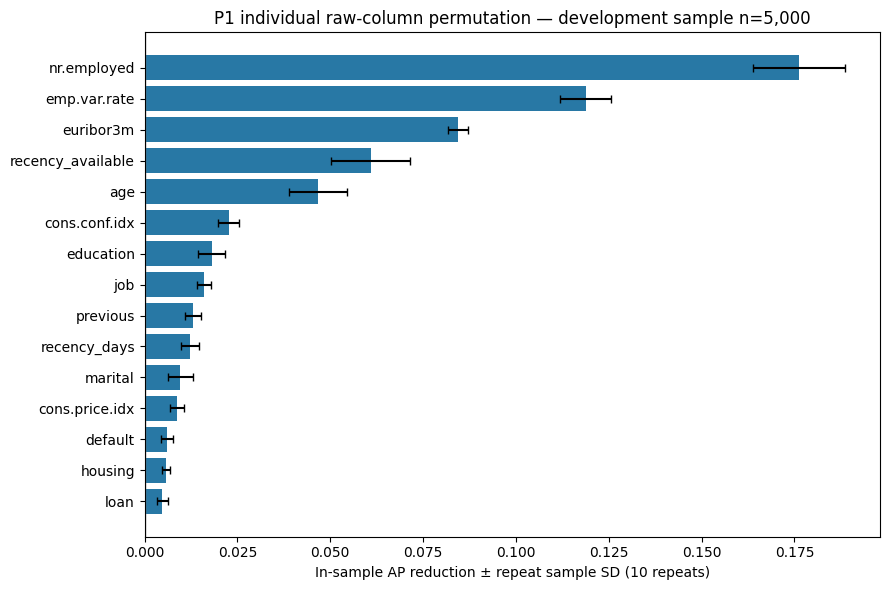

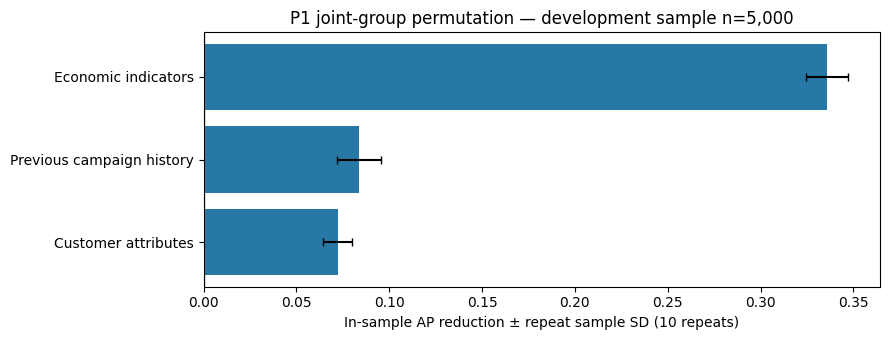

kind,feature_or_group,mean_AP_reduction,sample_SD,minimum,maximum
individual,nr.employed,0.176239,0.012367,0.153569,0.191672
individual,emp.var.rate,0.118862,0.006869,0.110704,0.130365
individual,euribor3m,0.084485,0.002679,0.079850,0.087501
individual,recency_available,0.060935,0.010651,0.048604,0.085530
individual,age,0.046798,0.007833,0.035083,0.062832
individual,cons.conf.idx,0.022663,0.002875,0.017913,0.026385
individual,education,0.018104,0.003620,0.011044,0.022723
individual,job,0.015972,0.001917,0.012960,0.019190
individual,previous,0.013001,0.002083,0.009249,0.016397
individual,recency_days,0.012304,0.002423,0.009449,0.017134


kind,feature_or_group,mean_AP_reduction,sample_SD,minimum,maximum
group,Economic indicators,0.335810,0.011211,0.312852,0.347088
group,Previous campaign history,0.083725,0.012011,0.069889,0.111219
group,Customer attributes,0.072181,0.007798,0.064194,0.086425


In [2]:
start=time.perf_counter();perms=[np.random.default_rng(42+r).permutation(len(X)) for r in range(10)]
ECON=['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed'];HISTORY=['previous','recency_available','recency_days'];CUSTOMER=['age','job','marital','education','default','housing','loan']
variants=[('individual',c,[c]) for c in FEATURES]+[('group','Economic indicators',ECON),('group','Previous campaign history',HISTORY),('group','Customer attributes',CUSTOMER)]
perm_rows=[]
for kind,name,columns in variants:
 for rep,order in enumerate(perms,start=1):
  shuffled=X.copy()
  for column in columns:shuffled[column]=X[column].to_numpy()[order]
  ap=float(average_precision_score(y,predict_dev('P1',shuffled)))
  perm_rows.append({'kind':kind,'feature_or_group':name,'repeat':rep,'baseline_AP_in_sample':baseline_ap,'permuted_AP':ap,'AP_reduction':baseline_ap-ap})
 print('Completed raw-column permutation:',name,flush=True)
perm=pd.DataFrame(perm_rows);perm_summary=perm.groupby(['kind','feature_or_group']).AP_reduction.agg(['mean','std','min','max']).reset_index()
perm_summary.columns=['kind','feature_or_group','mean_AP_reduction','sample_SD','minimum','maximum']
individual=perm_summary.loc[perm_summary.kind.eq('individual')].sort_values('mean_AP_reduction',ascending=False)
grouped=perm_summary.loc[perm_summary.kind.eq('group')].sort_values('mean_AP_reduction',ascending=False)
perm.to_csv(DATA/'13_permutation_repeats.csv',index=False,float_format='%.17g');perm_summary.to_csv(DATA/'13_permutation_summary.csv',index=False,float_format='%.17g')
FIGURE_LOG=[]
def savefig(filename,caption,source):
 plt.tight_layout();plt.savefig(FIGURES/filename,dpi=170,bbox_inches='tight')
 FIGURE_LOG.append({'filename':filename,'caption':caption,'source':source});plt.show()
for frame,filename,title in [(individual,'09_permutation_individual.png','P1 individual raw-column permutation'),(grouped,'10_permutation_groups.png','P1 joint-group permutation')]:
 d=frame.iloc[::-1];plt.figure(figsize=(9,6 if len(d)>5 else 3.5));plt.barh(d.feature_or_group,d.mean_AP_reduction,xerr=d.sample_SD,capsize=3,color='#2878A5');plt.axvline(0,color='gray',lw=1)
 plt.xlabel('In-sample AP reduction ± repeat sample SD (10 repeats)');plt.title(title+' — development sample n=5,000')
 savefig(filename,title+'; development-only in-sample, ten repeats; SD is permutation dispersion, not a generalization CI.','Phase 8; frozen P1, no refitting')
display(individual);display(grouped)



## 3. SHAP compatibility, logit reconstruction and original-field aggregation

Derive the exact encoded-column mapping from learned categories/output order and verify against the manifest. TreeExplainer uses tree_path_dependent reference and raw positive-class log-odds. Validate additivity against decision_function and sigmoid reconstruction against frozen pipeline probabilities. If unsupported, record the issue and use development-only model-agnostic ICE/PDP without changing the classifier.

Global summaries use a random300 subset of the explanation sample. Additional high/middle/low probability examples use predeclared score ranks, never outcomes. Group signed dummy SHAP per row, then average absolute sums for original-field display; this is encoded-game aggregation, not exact original-field coalition recomputation. Beeswarm color for categorical dummies indicates numeric bits, not ordinal category meaning. Dependence/local plots are descriptive model behavior, not intervention effects.


<string>:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
SHAP supported: True version: 0.50.0 issue: None


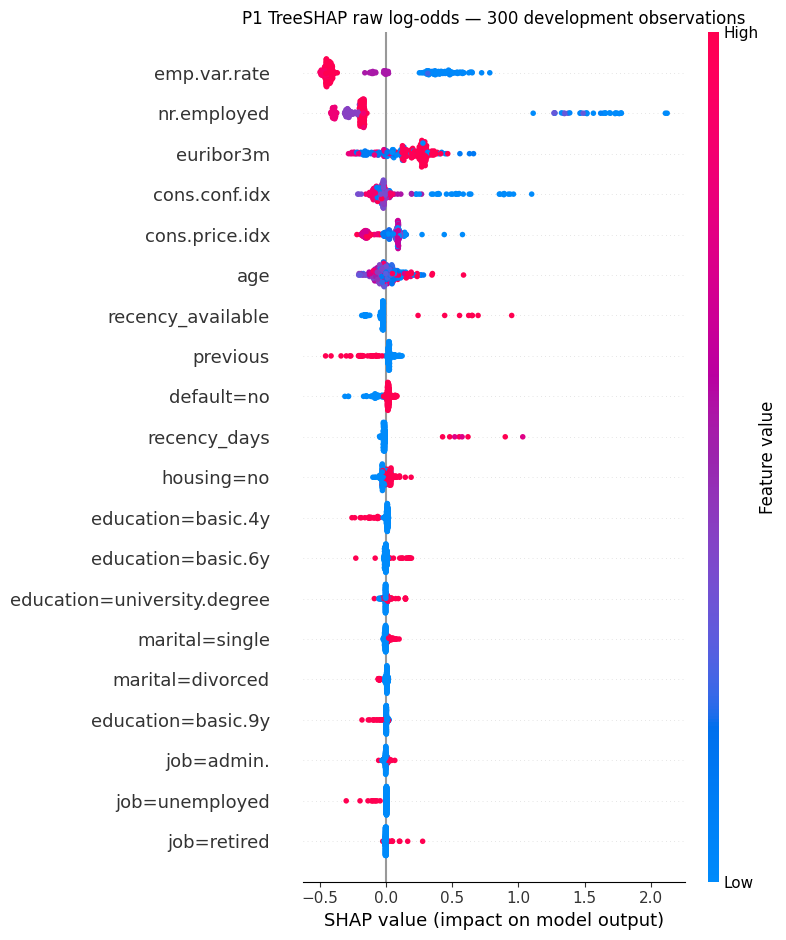

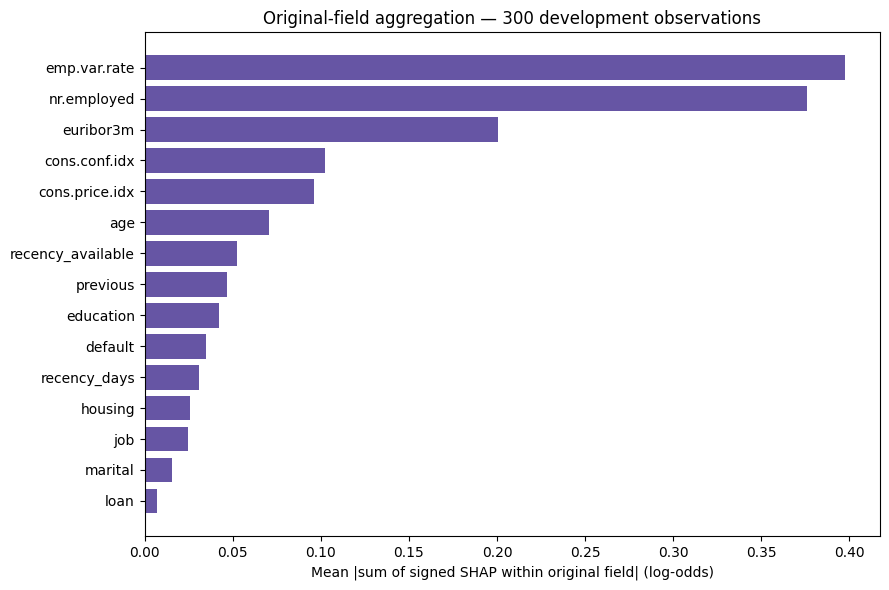

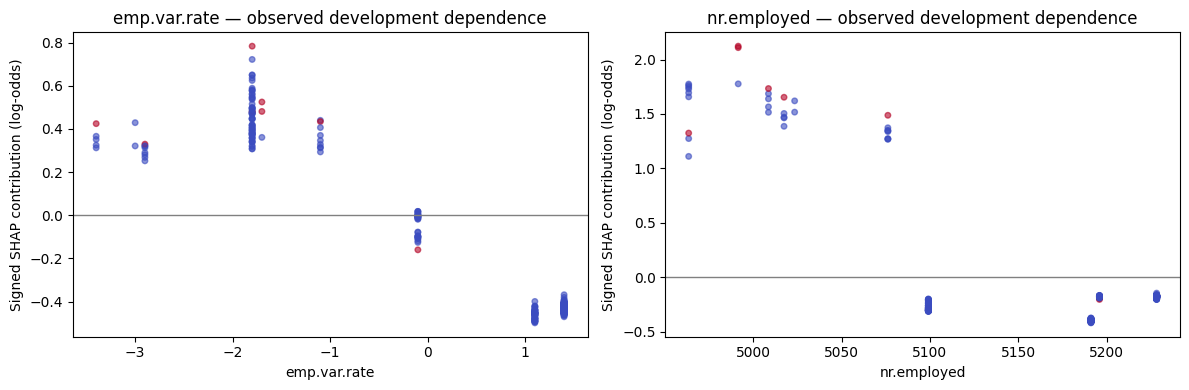

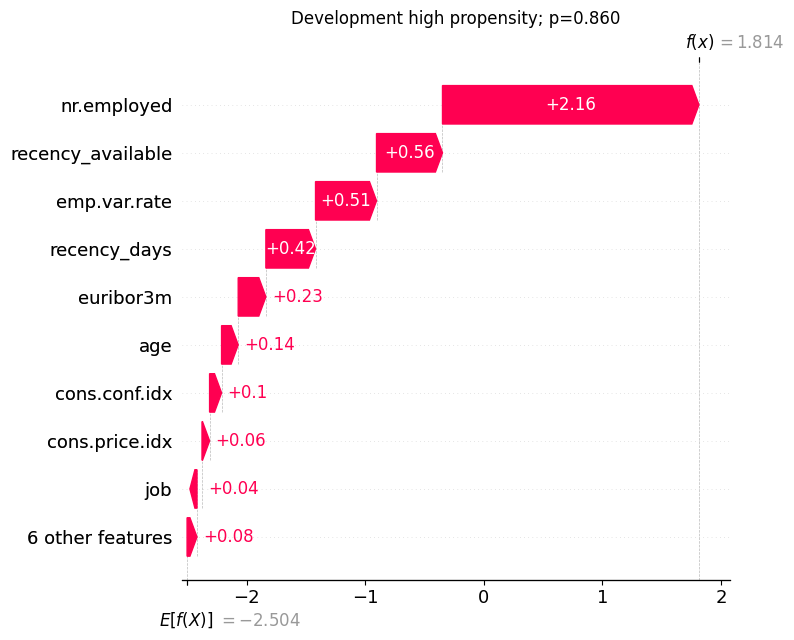

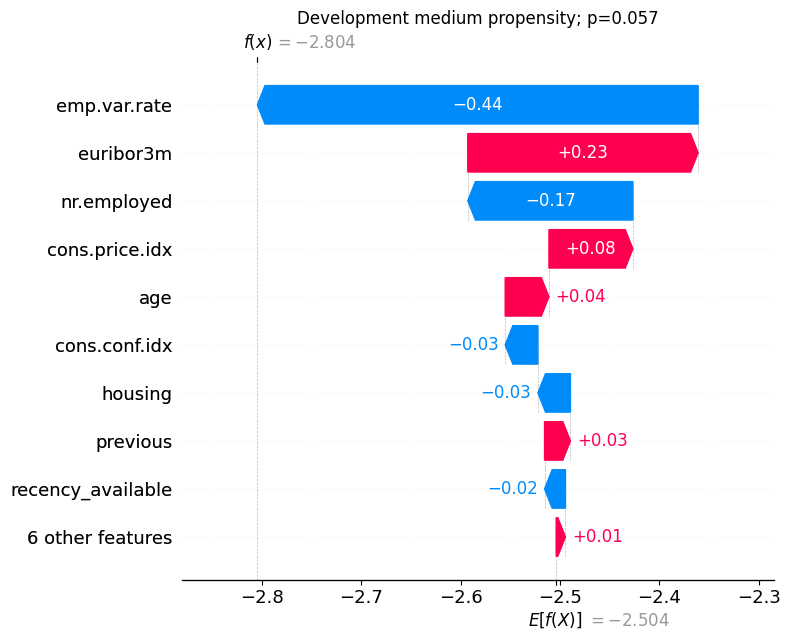

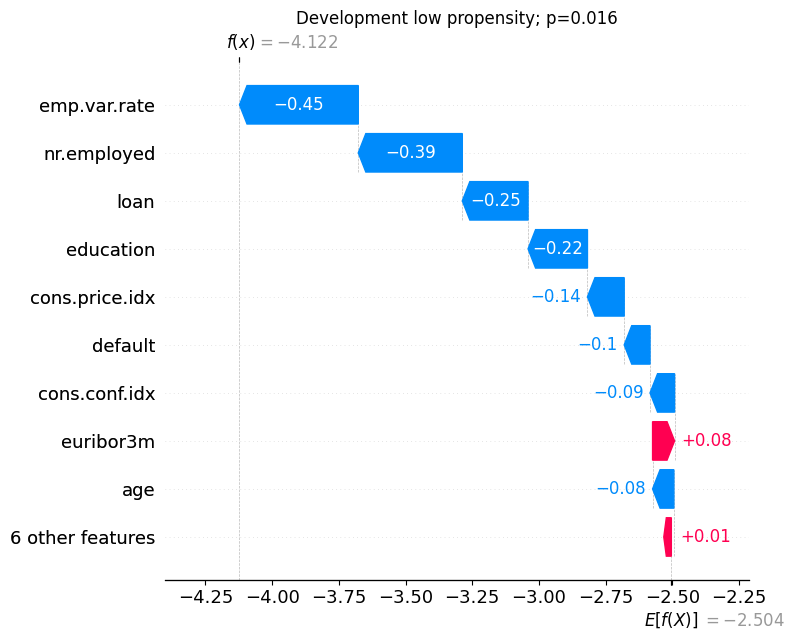

feature,mean_abs_signed_group_logodds
emp.var.rate,0.397556
nr.employed,0.376072
euribor3m,0.200518
cons.conf.idx,0.102447
cons.price.idx,0.096185
age,0.070380
recency_available,0.052469
previous,0.046534
education,0.042158
default,0.034844


example,cleaned_row_position,predicted_probability,base_log_odds,sum_contributions_log_odds,reconstructed_probability,leading_signed_contributions
high,40181,0.859851,-2.503824,4.317877,0.859851,nr.employed: +2.1633; recency_available: +0.5566; emp.var.rate: +0.5145; recency_days: +0.4189; euribor3m: +0.2334
medium,18081,0.057087,-2.503824,-0.300582,0.057087,emp.var.rate: -0.4434; euribor3m: +0.2317; nr.employed: -0.1661; cons.price.idx: +0.0845; age: +0.0440
low,1415,0.015950,-2.503824,-1.618390,0.015950,emp.var.rate: -0.4452; nr.employed: -0.3898; loan: -0.2464; education: -0.2226; cons.price.idx: -0.1377


In [3]:
# Exact transformed-to-original mapping: derive positions from learned encoder categories, not string heuristics.
def mapping_for(sid):
 pre=models[sid].named_steps['preprocessing'];ct=pre.named_steps['preprocessor'];names=pre.get_feature_names_out().tolist();enc=ct.named_transformers_['categorical']
 original=[];labels=[]
 for feature,levels in zip(CATEGORICAL,enc.categories_):
  for level in levels:original.append(feature);labels.append(feature+'='+str(level))
 original+=NUMERICAL+RECENCY;labels+=NUMERICAL+RECENCY
 expected=['categorical__'+v for v in enc.get_feature_names_out(CATEGORICAL)]+['numerical__'+v for v in NUMERICAL]+['recency__'+v for v in RECENCY]
 assert names==expected==manifest['scenarios'][sid]['preprocessing_statistics']['feature_names'] and len(names)==len(original)
 assert set(original)==set(FEATURES)
 return pd.DataFrame({'transformed_position':range(len(names)),'transformed_name':names,'original_feature':original,'display_name':labels})
feature_map=mapping_for('P1');feature_map.to_csv(DATA/'13_transformed_feature_mapping.csv',index=False)
# Selection uses only predicted scores and immutable row positions, never outcomes.
order=np.lexsort((X.index.to_numpy(),baseline_prob));local_positions={'high':int(order[-1]),'medium':int(order[len(order)//2]),'low':int(order[0])}
shap_rng=np.random.default_rng(42);global_positions=shap_rng.choice(len(X),size=300,replace=False)
explain_positions=np.unique(np.r_[global_positions,list(local_positions.values())]);shap_X=X.iloc[explain_positions].copy()
assert not set(shap_X.index).intersection(held)
pre=models['P1'].named_steps['preprocessing'];clf=models['P1'].named_steps['classifier']
with threadpool_limits(limits=1):z=pre.transform(shap_X)
assert z.shape[1]==len(feature_map) and np.isfinite(z).all() and clf.classes_.tolist()==[0,1]
shap_supported=False;shap_issue=None;shap_version=None;local_records=[];dependence_rows=[]
try:
 import shap
 shap_version=shap.__version__
 explainer=shap.TreeExplainer(clf,model_output='raw',feature_perturbation='tree_path_dependent')
 with threadpool_limits(limits=1):explanation=explainer(z,check_additivity=True)
 phi=np.asarray(explanation.values);base=np.asarray(explanation.base_values).reshape(-1)
 assert phi.shape==z.shape and len(base)==len(z)
 with threadpool_limits(limits=1):raw=clf.decision_function(z)
 raw_error=float(np.max(np.abs(base+phi.sum(axis=1)-raw)))
 prob=predict_dev('P1',shap_X);prob_error=float(np.max(np.abs(expit(base+phi.sum(axis=1))-prob)))
 assert raw_error<1e-6 and prob_error<1e-6
 # Sum SIGNED dummy attributions per row, then take mean absolute group sums.
 group_phi=np.column_stack([phi[:,feature_map.original_feature.eq(c).to_numpy()].sum(axis=1) for c in FEATURES])
 np.testing.assert_allclose(group_phi.sum(axis=1),phi.sum(axis=1),rtol=1e-12,atol=1e-12)
 global_locs=np.array([int(np.flatnonzero(explain_positions==p)[0]) for p in global_positions])
 shap_importance=pd.DataFrame({'feature':FEATURES,'mean_abs_signed_group_logodds':np.abs(group_phi[global_locs]).mean(axis=0)}).sort_values('mean_abs_signed_group_logodds',ascending=False)
 shap_importance.to_csv(DATA/'13_shap_grouped_importance.csv',index=False,float_format='%.17g')
 np.savez_compressed(DATA/'13_shap_values.npz',cleaned_row_positions=shap_X.index.to_numpy(),global_cleaned_positions=X.iloc[global_positions].index.to_numpy(),
  transformed_values=phi,base_values=base,grouped_signed_values=group_phi,transformed_data=z,original_features=np.array(FEATURES),transformed_names=feature_map.transformed_name.to_numpy(dtype=str))
 np.random.seed(42)
 shap.summary_plot(phi[global_locs],z[global_locs],feature_names=feature_map.display_name.tolist(),max_display=20,show=False)
 plt.title('P1 TreeSHAP raw log-odds — 300 development observations')
 savefig('11_shap_beeswarm.png','TreeSHAP encoded-feature beeswarm; raw log-odds for class 1; color is transformed feature value.','Phase 8; tree-path-dependent reference; development in-sample')
 d=shap_importance.iloc[::-1];plt.figure(figsize=(9,6));plt.barh(d.feature,d.mean_abs_signed_group_logodds,color='#6655A4');plt.xlabel('Mean |sum of signed SHAP within original field| (log-odds)');plt.title('Original-field aggregation — 300 development observations')
 savefig('12_shap_grouped_bar.png','Mean absolute signed-within-field SHAP sums; encoded-game aggregation, not a recomputed original-variable Shapley game.','Phase 8; development in-sample')
 top_numeric=[c for c in shap_importance.feature if c in NUMERICAL+['recency_days']][:2]
 fig,axes=plt.subplots(1,2,figsize=(12,4))
 for ax,feature in zip(axes,top_numeric):
  col=FEATURES.index(feature);values=shap_X.iloc[global_locs][feature].to_numpy();attribution=group_phi[global_locs,col]
  ax.scatter(values,attribution,c=shap_X.iloc[global_locs].recency_available,cmap='coolwarm',alpha=.6,s=16);ax.axhline(0,color='gray',lw=1)
  ax.set(xlabel=feature,ylabel='Signed SHAP contribution (log-odds)',title=feature+' — observed development dependence')
  dependence_rows.append({'feature':feature,'spearman_value_vs_SHAP':float(spearmanr(values,attribution).statistic)})
 savefig('13_shap_dependence.png','Observed numerical value versus signed original-field contribution; color indicates recency availability; associations, not intervention responses.','Phase 8; 300 development observations')
 for label,pos in local_positions.items():
  j=int(np.flatnonzero(explain_positions==pos)[0]);values=group_phi[j];top=np.argsort(-np.abs(values))[:5]
  record={'example':label,'cleaned_row_position':int(X.index[pos]),'predicted_probability':float(baseline_prob[pos]),'base_log_odds':float(base[j]),
   'sum_contributions_log_odds':float(values.sum()),'reconstructed_probability':float(expit(base[j]+values.sum())),
   'leading_signed_contributions':'; '.join(FEATURES[k]+': '+f'{values[k]:+.4f}' for k in top)}
  local_records.append(record)
  shap.plots.waterfall(shap.Explanation(values=values,base_values=float(base[j]),feature_names=FEATURES),max_display=10,show=False)
  plt.title('Development '+label+' propensity; p='+f'{baseline_prob[pos]:.3f}')
  savefig({'high':'14_shap_local_high.png','medium':'15_shap_local_medium.png','low':'16_shap_local_low.png'}[label],
   'Local '+label+' predicted-propensity example chosen by predeclared score rank, not observed outcome; grouped signed log-odds contributions.','Phase 8; development only; no causal intervention')
 shap_supported=True
except Exception as exc:
 shap_issue=type(exc).__name__+': '+str(exc)
 print('SHAP reliability check failed:',shap_issue,'; frozen classifier is not modified.')
 # Supported model-agnostic fallback: development-only ICE/PDP, fixed grid and sample, no fitting.
 top_numeric=[c for c in individual.feature_or_group if c in NUMERICAL][:2];ice_base=X.iloc[:100].copy()
 fig,axes=plt.subplots(1,2,figsize=(12,4))
 for ax,feature in zip(axes,top_numeric):
  grid=np.unique(np.quantile(X[feature],np.linspace(.05,.95,15)));curves=[]
  for val in grid:
   counterfactual=ice_base.copy();counterfactual[feature]=val;curves.append(predict_dev('P1',counterfactual))
  curves=np.array(curves);ax.plot(grid,curves[:,:15],color='gray',alpha=.15);ax.plot(grid,curves.mean(axis=1),color='#2878A5',lw=2);ax.set(xlabel=feature,ylabel='Frozen-model probability',title='Development ICE/PDP — artificial combinations')
 savefig('11_alternative_ice_pdp.png','Model-agnostic development ICE/PDP fallback; correlated/artificial combinations limit interpretation.','Phase 8; no refitting, not causal')
local_frame=pd.DataFrame(local_records);local_frame.to_csv(DATA/'13_local_explanations.csv',index=False)
print('SHAP supported:',shap_supported,'version:',shap_version,'issue:',shap_issue)
if shap_supported:display(shap_importance);display(local_frame)



## 4. Frozen LR coefficient reference

Verify learned output names/coefficients align, and reconstruct logits/probabilities on development observations. Numerical coefficients use training-standardized units; available-only recency scaling and separate unscaled availability remain approved. Full one-hot has no omitted reference, so category substitutions require coefficient differences. Correlated macro predictors, L2 shrinkage and conditional model structure constrain sign/magnitude interpretation. Coefficients are not causal or directly actionable customer effects.


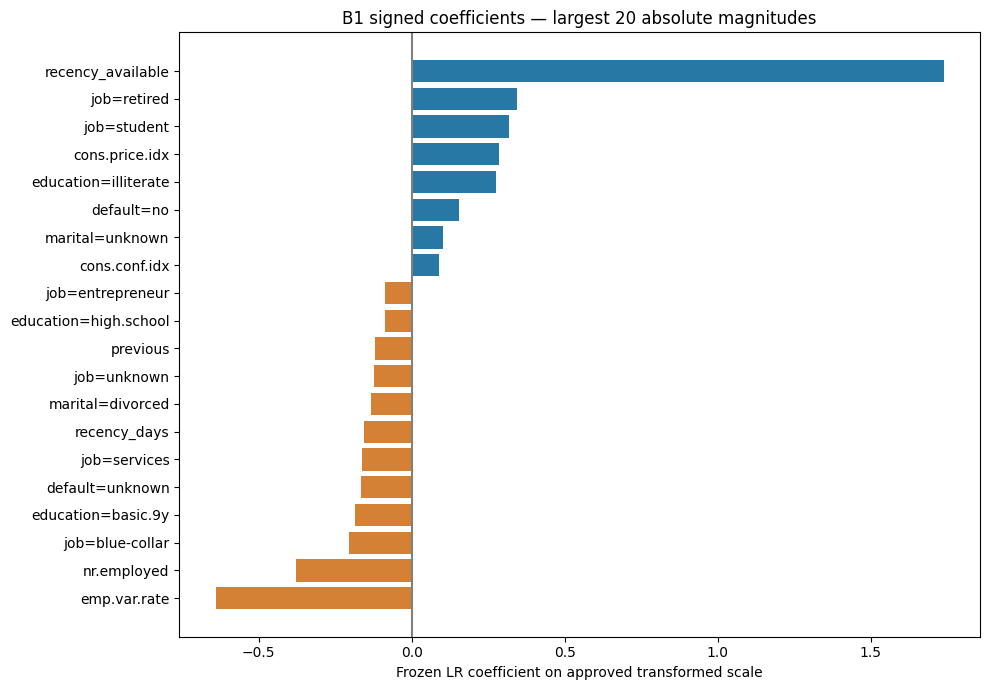

transformed_position,transformed_name,original_feature,display_name,coefficient,absolute_coefficient,interpretation_unit
41,recency__recency_available,recency_available,recency_available,1.737389,1.737389,one unscaled binary indicator
35,numerical__emp.var.rate,emp.var.rate,emp.var.rate,-0.640220,0.640220,one training-fitted standard deviation; recency conditional on available
39,numerical__nr.employed,nr.employed,nr.employed,-0.378930,0.378930,one training-fitted standard deviation; recency conditional on available
5,categorical__job_retired,job,job=retired,0.344794,0.344794,one encoded category indicator (valid substitution requires coefficient difference)
8,categorical__job_student,job,job=student,0.317715,0.317715,one encoded category indicator (valid substitution requires coefficient difference)
36,numerical__cons.price.idx,cons.price.idx,cons.price.idx,0.285707,0.285707,one training-fitted standard deviation; recency conditional on available
20,categorical__education_illiterate,education,education=illiterate,0.275833,0.275833,one encoded category indicator (valid substitution requires coefficient difference)
1,categorical__job_blue-collar,job,job=blue-collar,-0.204580,0.204580,one encoded category indicator (valid substitution requires coefficient difference)
18,categorical__education_basic.9y,education,education=basic.9y,-0.185861,0.185861,one encoded category indicator (valid substitution requires coefficient difference)
25,categorical__default_unknown,default,default=unknown,-0.166392,0.166392,one encoded category indicator (valid substitution requires coefficient difference)


In [4]:
lr_map=mapping_for('B1');lr=models['B1'].named_steps['classifier'];coef=lr.coef_[0];assert len(coef)==len(lr_map) and lr.classes_.tolist()==[0,1]
lr_frame=lr_map.copy();lr_frame['coefficient']=coef;lr_frame['absolute_coefficient']=np.abs(coef)
lr_frame['interpretation_unit']=['one encoded category indicator (valid substitution requires coefficient difference)' if n.startswith('categorical__') else ('one unscaled binary indicator' if n.endswith('recency_available') else 'one training-fitted standard deviation; recency conditional on available') for n in lr_frame.transformed_name]
lr_frame.to_csv(DATA/'13_lr_coefficients.csv',index=False,float_format='%.17g')
lr_X=shap_X.copy();lr_z=models['B1'].named_steps['preprocessing'].transform(lr_X)
logit=lr_z@coef+float(lr.intercept_[0])
with threadpool_limits(limits=1):np.testing.assert_allclose(logit,lr.decision_function(lr_z),rtol=1e-12,atol=1e-12)
lr_prob=predict_dev('B1',lr_X);np.testing.assert_allclose(expit(logit),lr_prob,rtol=1e-12,atol=1e-12)
lr_top=lr_frame.sort_values('absolute_coefficient',ascending=False).head(20).sort_values('coefficient')
plt.figure(figsize=(10,7));plt.barh(lr_top.display_name,lr_top.coefficient,color=np.where(lr_top.coefficient>=0,'#2878A5','#D48135'));plt.axvline(0,color='gray');plt.xlabel('Frozen LR coefficient on approved transformed scale');plt.title('B1 signed coefficients — largest 20 absolute magnitudes')
savefig('17_lr_coefficients.png','B1 coefficients on standardized numerical/full-one-hot scale; not causal effects or unadjusted original-unit importance.','Phase 8; frozen B1, alignment checked with development logits')
display(lr_frame.sort_values('absolute_coefficient',ascending=False).head(15))



## 5. Preservation and explanation report

Verify every old artifact's bytes and loaded estimators' in-memory hashes remain unchanged. Save mappings, sample indices, per-repeat permutation AP, signed SHAP arrays, local records, LR coefficients and audit metadata in figures/data. No original source/result/model is rewritten. The summary explicitly separates observed reliance, Phase 6A nested ablation evidence and unresolved timing hypotheses. All predictors stay Provisional; importance establishes neither availability, fairness, robustness nor causal impact. No commit/push or new development.


In [5]:
for sid,m in models.items():assert joblib.hash(m)==model_state[sid],'In-memory frozen estimator changed'
for n,h in protected.items():assert sha(PROJECT_DIR/n)==h,n+' changed'
analysis={'source_main':SOURCE_MAIN,'development_rows':32940,'sample_rows':len(X),'sample_positives':int(y.sum()),'sample_prevalence':float(y.mean()),
 'sample_seed':42,'sampling':'class-count-proportional without replacement; shuffled, no evaluation split',
 'baseline_AP_in_sample':baseline_ap,'permutation_repeats':10,'permutation_seed_rule':'default_rng(42+repeat_zero_based); same order across all fields/groups in each repeat',
 'permutation_seconds':time.perf_counter()-start,'in_sample_descriptive_not_validation':True,'groups':{'economic':ECON,'history':HISTORY,'customer':CUSTOMER},
 'shap_supported':shap_supported,'shap_version':shap_version,'shap_issue':shap_issue,'SHAP_global_sample':300,'SHAP_total_explained':len(shap_X),
 'SHAP_reference':'tree_path_dependent training node cover; model_output=raw positive-class log-odds',
 'SHAP_signed_aggregation':'sum transformed signed values within original field per observation, then mean absolute row sums; not original-field coalition recomputation',
 'local_selection':'highest, middle and lowest P1 predicted probability within development sample; cleaned-row position ties; no observed outcomes',
 'dependence_spearman':dependence_rows,'models_unchanged':True,'preprocessing_unchanged':True,'heldout_rows_or_predictions_parsed':False,
 'new_fit_calls':0,'new_hyperparameter_searches':0,'versions':{'sklearn':sklearn.__version__,'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__},
 'development_prediction_calls':CALLS,'protected_artifacts_sha256':protected}
if shap_supported:analysis.update({'SHAP_max_logit_additivity_error':raw_error,'SHAP_max_probability_reconstruction_error':prob_error})
dump(DATA/'13_explainability_audit.json',analysis)
_inventory_path=DATA/'figure_inventory.json'
_previous_inventory=json.loads(_inventory_path.read_text()) if _inventory_path.exists() else []
_merged_inventory={v['filename']:v for v in _previous_inventory+FIGURE_LOG}
dump(_inventory_path,sorted(_merged_inventory.values(),key=lambda v:v['filename']))
shap_text=mdtable(shap_importance) if shap_supported else 'SHAP was not reliable: '+str(shap_issue)+'. Development-only ICE/PDP fallback was used without changing the estimator.'
local_text=mdtable(local_frame) if len(local_frame) else 'Local SHAP unavailable; the technical failure is recorded above.'
summary=f"""# Phase 8A — Frozen-model explainability and interpretation

## Scope, integrity and boundaries

Source merged main **{SOURCE_MAIN}** includes Phase 7. Release-gate PASS chronology, all four frozen model hashes and archived results digests verified. Only trusted frozen P1 (Full original HGB) and B1 (Full original LR) were loaded. No training, hyperparameter/threshold selection, calibration or held-out evaluation occurred. Fit methods were blocked in this session. Every previous project file is unchanged, and both loaded estimators have unchanged in-memory joblib hashes. Held-out row-level predictions were only byte-hashed for integrity, never parsed; final reporting uses archived aggregate tables only.

All 15 predictors remain Provisional. These explanations do not establish deployment readiness. This is **in-sample descriptive explanation**: final models had already fitted all 32,940 development observations. Neither an explanation sample nor permutation repeats create independent validation.

## Predeclared development sampling and permutation method

Sample: **{len(X)} development rows, {int(y.sum())} positives ({y.mean():.6f})**, class-count-proportional sampling without replacement, seed42; development prevalence {dev.y.mean():.6f}. Frozen P1 sample AP is **{baseline_ap:.6f}, in-sample**, not a replacement for nested CV or held-out AP. Sample row positions are saved under figures/data/; no held-out positions enter analysis.

Each original raw input field is permuted through the complete unchanged pipeline ten times, using default_rng(42+repeat_zero_based). A repeat's row permutation is shared across all fields/groups, giving paired perturbations. Mean AP reduction = original sample AP minus permuted AP; sample SD (ddof=1) measures Monte Carlo repeat dispersion, not a sampling/generalization confidence interval. Small/negative values are retained, not clipped. Labels and class prevalence stay fixed.

{mdtable(individual)}

![Individual permutation importance](figures/09_permutation_individual.png)

**Figure 9.** Original-column permutation AP reductions; development-only in-sample; ten repeats ± repeat SD. Source: Phase 8 frozen P1.

## Joint-group permutation sensitivity

{mdtable(grouped)}

![Joint permutation](figures/10_permutation_groups.png)

**Figure 10.** Joint-group permutation, development-only in-sample. One shared row order moves all group columns together, preserving within-group relationships.

Economic group: {', '.join(ECON)}. History group: {', '.join(HISTORY)}. Customer group: {', '.join(CUSTOMER)}. Joint permutations preserve within-group structure but break relationships with the outcome and other groups. Individual recency-field shuffling can create impossible availability/day combinations; such AP reductions are model perturbation sensitivities, not valid customer interventions. The joint history group is more coherent for this reason. Economics are correlated and can substitute/shared-information; small individual values need not imply no joint contribution. Do not sum individual drops as the group contribution.

Phase 6A separately retuned/refit models after removing feature groups, with nested out-of-sample evaluation: HGB AP 0.448145 Full, 0.351146 without economics, 0.389129 without history, 0.232569 customer-only. Those losses (0.096999 /0.059017 /0.215576) are **not numerically interchangeable** with frozen-model in-sample permutation drops. Compare qualitative reliance only; the estimator, refitting allowance, cohort and evaluation design differ. No new ablation was performed.

## SHAP compatibility, output scale and mapping

SHAP support: **{shap_supported}**; version {shap_version}; issue {shap_issue}. SHAP was initially absent; shap0.50.0 plus numba0.63.1, llvmlite0.46.0, slicer0.0.8, tqdm4.67.1 and cloudpickle3.1.2 were installed in scratch space. Approved sklearn1.8.0/NumPy2.3.5/pandas2.2.3 and frozen files were not changed. Colab instructions pin compatible versions. Hosted Colab itself was not exercised.

TreeExplainer uses tree_path_dependent training-node cover and model_output='raw'. Binary output is **positive-class log-odds**, not probability units. Sum of base and transformed SHAP values was checked against the frozen HGB decision_function, and its logistic transform against class-1 probability. No interventional background sample or causal interpretation is claimed. Training-path reference is not the population mean probability and depends on the fitted model/training distribution.

The global explanation sample has 300 random development-sample observations (seed42). Additional high/middle/low score-selected examples bring unique explained rows to {len(shap_X)}; global summaries use only the random 300, not deliberately added extremes. Transformed names/order were validated against learned encoder categories and the manifest, then mapped to all 15 original fields. Mapping is saved in figures/data/13_transformed_feature_mapping.csv.

For original-field summaries, **sum SIGNED dummy SHAP values within a field per row, then compute mean absolute sums**. This preserves the local total logit decomposition, but is an aggregation of the encoded-feature game, not an exact new original-variable coalition SHAP calculation. It can cancel opposing dummy contributions; it differs from summing arbitrary mean absolute dummy values. Correlation/reference choices and off-manifold feature coalitions constrain interpretation.

{shap_text}

![SHAP beeswarm](figures/11_shap_beeswarm.png)

**Figure 11.** Encoded-feature SHAP beeswarm, raw log-odds, random 300 development observations; dummy color indicates indicator values, not ordered category meaning. Source: frozen P1, Phase 8.

![Grouped signed SHAP](figures/12_shap_grouped_bar.png)

**Figure 12.** Mean absolute signed-within-original-field aggregation on the same 300 rows; not independent contribution validation.

![SHAP dependence](figures/13_shap_dependence.png)

**Figure 13.** Observed development numerical values versus signed original-field logit contributions; recency availability colors; associations, not effects of changing a customer's value.

## Representative local explanations

{local_text}

Examples use only P1 predicted probability ranks and immutable cleaned-row tie breaks: high=maximum, medium=middle ordered score, low=minimum in the 5,000-row explanation sample. Observed y does not choose or validate examples. The local sum reconstructs the frozen model prediction, not why a real customer acted or what changing one attribute would cause.

![High propensity](figures/14_shap_local_high.png)

**Figure 14.** Highest-scored development example, grouped signed log-odds decomposition.

![Middle propensity](figures/15_shap_local_medium.png)

**Figure 15.** Middle-scored development example, same predeclared procedure.

![Low propensity](figures/16_shap_local_low.png)

**Figure 16.** Lowest-scored development example, not an outcome-selected example.

## Frozen B1 coefficient interpretation

All {len(lr_frame)} transformed coefficients align exactly to approved output names. Reconstructed transformed dot-product logits and logistic probabilities match B1 outputs on development data. Intercept: {float(lr.intercept_[0]):.6f}.

{mdtable(lr_frame.sort_values('absolute_coefficient',ascending=False).head(15))}

![LR coefficients](figures/17_lr_coefficients.png)

**Figure 17.** Largest absolute frozen B1 coefficients with sign; standardized numerical/full-one-hot representation.

A positive coefficient raises the fitted conditional log-odds holding other encoded inputs fixed; negative lowers it. Numerical coefficients refer to one training-fitted standard deviation, with recency scaling estimated only where available; availability is a separate unscaled bit. Full one-hot includes every level, so individual dummy coefficients have no omitted reference category and are regularization-dependent alongside the intercept. A valid category contrast uses the difference of category coefficients. Do not read coefficient magnitude as unadjusted original-unit importance or treat category flags as independent interventions. Correlated macro indicators can redistribute/flip conditional coefficients; signs do not establish causal economic effects. L2 shrinkage and model linearity differ from HGB's nonlinear attribution behavior.

## Validity, source timing and business implications

Explainability can reveal predictive reliance on macro context/history/customer records, not confirm campaign-start availability. Economic values can proxy shared campaign periods; correlations can distribute importance. Missing IDs/dates prevent verifying unique-customer and future-period generalization. Customer/status snapshots, history cutoff, recency reference date, economic release/revision vintage and target window remain unresolved in 10_feature_availability_matrix.md. No importance value verifies fairness, robustness, availability or causality.

For limited outreach resources, explanations help communicate the frozen ranking's information requirements and data-governance priorities. They do not recommend changing a customer's demographic/status/history to obtain a subscription, prove incrementality, justify ROI or select a new policy. The original P1 remains sole primary; archived final performance and predeclared top-10% illustrative policy remain unchanged.

Detailed sample indices, repeat-level APs, mappings, signed SHAP arrays, local records, coefficients and audit metadata are in figures/data/. Previous models/results/source files remain byte-identical. No retraining, held-out record parsing/scoring, post-test tuning, commit or push occurred. Stop after interpretation/reporting.
"""
observed_findings = "## Observed findings and interpretation\n\nThe strongest individual P1 permutation sensitivities are nr.employed (AP drop 0.176239 ± 0.012367 repeat SD), emp.var.rate (0.118862 ± 0.006869) and euribor3m (0.084485 ± 0.002679). Joint economic sensitivity is 0.335810 ± 0.011211, ahead of previous campaign history (0.083725 ± 0.012011) and customer attributes (0.072181 ± 0.007798). These in-sample perturbation magnitudes must not replace or be added to nested feature-ablation losses.\n\nThe leading signed-within-field mean absolute SHAP log-odds contributions are emp.var.rate 0.397556, nr.employed 0.376072 and euribor3m 0.200518. Thus both methods point to macro context, while allocating correlated information differently. The dependence plots do not imply a simple economic law: emp.var.rate has negative observed value/contribution association, whereas nr.employed's association is weaker and positive here. Neither is a causal intervention response.\n\nSHAP was reliable in this environment: maximum logit additivity error 5.33e-15 and probability reconstruction error 1.17e-15. A plotting-only FutureWarning concerned global RNG seeding; seeded jitter was reproducible in the current package version. No classifier modification or fallback was required. Example probabilities high/middle/low are 0.859851 / 0.057087 / 0.015950, selected without outcomes. All explanation observations are development rows.\n\nB1's recency-availability coefficient is +1.737389, emp.var.rate -0.640220 and nr.employed -0.378930 on their approved transformed scales. These conditional linear signs are not causal and need not match nonlinear SHAP dependence. Rare categories, such as education=illiterate (18 cleaned records), particularly limit substantive interpretation of individual category coefficients.\n"
_summary_title,_summary_rest=summary.split("\n",1)
summary=_summary_title+"\n\n"+observed_findings+"\n"+_summary_rest.lstrip("\n")
(PROJECT_DIR/'13_model_explainability_summary.md').write_text(summary)
print('Development-only explainability completed. Protected sources/models/results unchanged; no fit calls or held-out row/prediction parsing.')


Development-only explainability completed. Protected sources/models/results unchanged; no fit calls or held-out row/prediction parsing.


## Observed findings and interpretation

The strongest individual P1 permutation sensitivities are nr.employed (AP drop 0.176239 ± 0.012367 repeat SD), emp.var.rate (0.118862 ± 0.006869) and euribor3m (0.084485 ± 0.002679). Joint economic sensitivity is 0.335810 ± 0.011211, ahead of previous campaign history (0.083725 ± 0.012011) and customer attributes (0.072181 ± 0.007798). These in-sample perturbation magnitudes must not replace or be added to nested feature-ablation losses.

The leading signed-within-field mean absolute SHAP log-odds contributions are emp.var.rate 0.397556, nr.employed 0.376072 and euribor3m 0.200518. Thus both methods point to macro context, while allocating correlated information differently. The dependence plots do not imply a simple economic law: emp.var.rate has negative observed value/contribution association, whereas nr.employed's association is weaker and positive here. Neither is a causal intervention response.

SHAP was reliable in this environment: maximum logit additivity error 5.33e-15 and probability reconstruction error 1.17e-15. A plotting-only FutureWarning concerned global RNG seeding; seeded jitter was reproducible in the current package version. No classifier modification or fallback was required. Example probabilities high/middle/low are 0.859851 / 0.057087 / 0.015950, selected without outcomes. All explanation observations are development rows.

B1's recency-availability coefficient is +1.737389, emp.var.rate -0.640220 and nr.employed -0.378930 on their approved transformed scales. These conditional linear signs are not causal and need not match nonlinear SHAP dependence. Rare categories, such as education=illiterate (18 cleaned records), particularly limit substantive interpretation of individual category coefficients.
